# Домашняя работа № 2: NYC Taxi

В этой домашней работе вам предстоит решить задачу **многоклассовой классификации**: предсказать диапазон длительности поездки на такси в Нью-Йорке.

Перед началом рекомендуем ознакомиться с вводной частью: здесь есть напоминание о EDA, небольшое введение в **feature engineering** и примеры работы с признаками. Затем идут постановка задачи, требования и рекомендации. Свой исследовательский notebook можно организовать так, как вам удобно.

[Вводная часть](#preparation) · [Задание](#assignment) · [Рекомендации](#recommendations)

<a id="preparation"></a>
## I. Подготовка

### 1. EDA: знакомство с данными

**Exploratory Data Analysis (EDA)** — исследование данных перед построением модели. Мы знакомимся с устройством таблицы, изучаем распределения и связи между переменными, проверяем качество измерений и формулируем вопросы для дальнейшего исследования.

Здесь помогают и простые методы `pandas`, и визуализации. Главное — понимать, **на какой вопрос отвечает каждая таблица или график** и что мы узнали из результата.

#### От вопроса к решению

Полезно мыслить EDA как небольшим исследовательским циклом:

**Вопрос → подходящая сводка или график → наблюдение → гипотеза или практическое решение.**

Например, если в таблице есть площадь недвижимости и цена продажи, можно спросить: *«Как связаны площадь и цена? Одинакова ли эта связь в разных районах?»* Для ответа пригодится диаграмма рассеяния, на которой точки окрашены по району. Но сам график ещё не объясняет причин различий. Он лишь даёт повод сформулировать следующую гипотезу.

Хороший EDA заканчивается не фразой «построен график», а выводом о том, **что мы узнали и что проверим дальше**.

#### Небольшой пример: объявления о недвижимости

Сгенерируем небольшой учебный набор данных о площади, районе и цене объектов недвижимости.

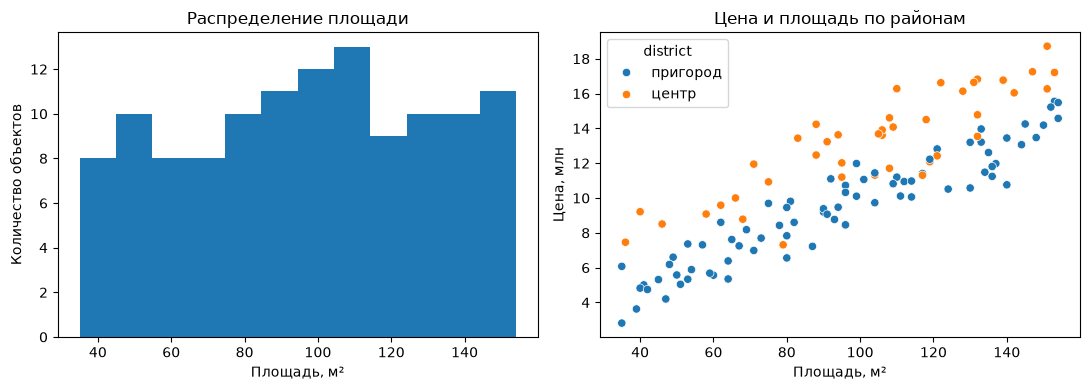

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(7)
n = 120

houses = pd.DataFrame({
    "area_m2": rng.integers(35, 155, size=n),
    "district": rng.choice(["центр", "пригород"], size=n, p=[0.4, 0.6]),
})

houses["price_mln"] = (
    1.5
    + 0.085 * houses["area_m2"]
    + 3.0 * (houses["district"] == "центр")
    + rng.normal(0, 1.2, size=n)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(houses["area_m2"], bins=12)
axes[0].set(title="Распределение площади", xlabel="Площадь, м²",
            ylabel="Количество объектов")

sns.scatterplot(data=houses, x="area_m2", y="price_mln",
                hue="district", ax=axes[1])
axes[1].set(title="Цена и площадь по районам",
            xlabel="Площадь, м²", ylabel="Цена, млн")
plt.tight_layout()

Первый график отвечает на вопрос, **какие площади представлены в таблице**. Он нужен, чтобы не рассуждать о «типичном доме», не зная диапазона наблюдений.

Второй показывает две особенности сгенерированных данных: цена в целом растёт с площадью, а при сопоставимой площади объекты в центре обычно дороже. Это уже более содержательное наблюдение, чем простая средняя цена по каждому району: средние могли бы различаться ещё и потому, что размеры домов в районах неодинаковы.

Из этого примера можно сформулировать гипотезу: *«При прогнозировании цены важно учитывать не только площадь, но и район; возможно, полезно исследовать их совместное влияние».* Проверять её нужно на данных и моделях, а не объявлять доказанной по одному рисунку.

**Чего мы не узнали?** Мы не доказали, что расположение *причинно* увеличивает цену, и не выяснили, улучшит ли любой новый признак качество будущей модели. В реальных данных на такие различия могут влиять другие переменные; здесь же закономерность специально заложена в генератор.

#### На что смотреть в собственных данных

Начните с устройства таблицы. Что означает одна строка? Как измерены переменные? В какой момент становятся известны их значения? Обратите внимание на необычные коды категорий, пропуски и повторы.

Дальше полезно исследовать:

- **Целевую переменную:** доли классов, дисбаланс, наличие очень редких категорий.
- **Распределения отдельных признаков:** типичные значения, разброс, длинные хвосты и необычные наблюдения.
- **Связи признаков между собой и с целью:** различия между группами, взаимосвязи числовых величин, неоднородность в разных частях данных.
- **Качество данных:** пропуски, невозможные значения, повторные записи, несогласованность единиц измерения и типов.

##### Выбросы и экстремальные значения

Большое или редкое значение ещё не означает ошибку. Полезно различать несколько случаев:

- **Ошибка записи или измерения.** Отрицательная площадь или невозможная дата обычно требуют исправления, если достоверное значение известно; в противном случае можно рассмотреть пропуск или исключение записи, объяснив решение.
- **Редкое, но реальное наблюдение.** Например, очень большой дом может быть частью интересующей нас популяции. Удаление таких объектов способно сделать модель хуже именно там, где она нужна.
- **Корректное значение, неудобное для модели.** Длинный хвост может влиять на масштабирование и расстояния между объектами. Иногда помогают логарифмирование, `RobustScaler` или ограничение экстремальных значений (*clipping*). Эти варианты нужно сравнивать экспериментально; `RobustScaler` сам значения не обрезает.

Не существует универсального правила «всё за 1,5 IQR удалить». Сначала выясните происхождение экстремальных наблюдений, затем предложите способ обработки и проверьте его влияние на качество. Статистики преобразований следует оценивать только на соответствующей обучающей части.

Для графиков выбирайте подходящий масштаб и осмысленные группы: иногда логарифмическая ось или отдельный график хвоста информативнее, чем удаление неудобных точек.

#### Как записывать выводы

Хороший EDA — это несколько содержательных наблюдений с объяснением, **почему они важны для моделирования**. Не нужно строить графики ради количества; стройте столько, сколько помогает ответить на ваши вопросы.

Для важных результатов полезно записать:

1. **Что вы увидели?** Наблюдение, подтверждённое числом, таблицей или графиком.
2. **Почему это важно?** Например, для качества данных, выбора метрики или представления признаков.
3. **Что будете делать дальше?** Какую гипотезу проверите или какое решение примете.

Например, фраза «на scatterplot видна зависимость цены от площади» мало о чём говорит. Полезнее заметить, что связь площади и цены выглядит по-разному для районов, и предложить проверить, помогает ли учёт района модели. График подсказывает гипотезу; пользу для прогноза покажет эксперимент.

##### Материалы по EDA

**На русском:**

- [ODS — Первичный анализ данных с Pandas](https://habr.com/ru/companies/ods/articles/322626/).
- [ODS — Визуализация данных с Python](https://habr.com/ru/companies/ods/articles/323210/).

Это хорошие вводные статьи. Они написаны несколько лет назад: основные идеи актуальны, но отдельные вызовы библиотек, скриншоты и интерфейсы могут отличаться от современных версий.

**На английском:**

- [mlcourse.ai — Exploratory Data Analysis with Pandas](https://mlcourse.ai/book/topic01/topic01_pandas_data_analysis.html) и [Visual Data Analysis](https://mlcourse.ai/book/topic02/topic02_visual_data_analysis.html) — обновлённое учебное изложение.
- [From Data to Viz](https://www.data-to-viz.com/) — как выбрать вид графика и каких визуальных ловушек избегать.
- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html) — практические примеры распределений, связей и категориальных графиков.
- [A Practical Guide to EDA with Python (2024)](https://datos.gob.es/en/conocimiento/practical-introductory-guide-exploratory-data-analysis-python) — последовательный практикум с отдельным обсуждением пропусков и выбросов.

Читать все материалы целиком необязательно. Используйте их как справочник и источник идей.

### 2. Feature engineering: новые представления исходных данных

Иногда закономерность уже видна при EDA, но исходные столбцы не позволяют алгоритму удобно её использовать. Тогда мы можем создать **новые признаки из имеющейся информации**: рассчитать отношение величин, применить преобразование, объединить категории или описать совместное влияние нескольких факторов.

**Feature engineering (FE)** — конструирование и преобразование признаков с учётом смысла данных и устройства модели. Польза каждого преобразования проверяется экспериментально.

#### Какие задачи решают разные приёмы

| Приём | Пример |
|---|---|
| **Preprocessing** | Заполнение пропусков, One-Hot Encoding, масштабирование числовых признаков |
| **Feature engineering** | Отношение площади здания к площади участка, взаимодействие площади с районом |
| **Feature selection** | Отбор части признаков вручную или по результатам модели; например, L1-регуляризация в логистической регрессии может обнулить коэффициенты, после чего признаки можно отобрать через `SelectFromModel` |

Границы между preprocessing и FE не всегда строгие. Важнее понимать, **что меняется в представлении данных и зачем**.

##### Примеры feature engineering

- **Нелинейные преобразования:** `log1p(x)` для величины с длинным правым хвостом, квадрат величины, корень.
- **Отношения и разности:** площадь здания / площадь участка; доходы минус расходы; доля успешных попыток.
- **Взаимодействия:** площадь × индикатор района, возраст × категория товара; эффект одного признака может зависеть от другого.
- **Бинарные индикаторы:** «значение выше заданного порога», «характеристика отсутствует», «условие выполнено».
- **Интервалы и группировки:** преобразовать непрерывную величину в категории или объединить редкие категории, если для этого есть смысл.
- **Признаки из даты и времени:** год, месяц, день недели, время с момента известного события.
- **Агрегаты нескольких измерений:** сумма, среднее, минимум, максимум, разброс — если исходные измерения доступны к моменту прогноза.
- **Доменные показатели:** коэффициенты, индексы и нормировки, имеющие смысл в конкретной предметной области.

Добавление новых признаков не гарантирует повышения качества. Иногда оно только добавляет шум или меняет геометрию данных неудачным образом.

#### Пример: площадь и район

Вернёмся к недвижимости. Для примера создадим новый синтетический набор: цена зависит от площади дома, участка, года постройки и района. Кроме того, **стоимость дополнительного квадратного метра различается между районами**.

Обычная линейная модель с отдельными столбцами `area_m2` и `district` оценивает один общий коэффициент при площади. Проверим, помогает ли признак их взаимодействия.

Рассмотрим два варианта:

- `area_share = area_m2 / plot_m2` — отношение площадей.
- `area_center = area_m2 × I(район = центр)` — дополнительный вклад площади в центральном районе.

Здесь `I(условие)` равно единице, если условие выполняется, и нулю иначе. Например, для дома площадью 120 м² в центре `area_center = 120`, а в пригороде `0`.

Из года постройки также можно получить возраст дома на фиксированную дату. Но преобразование `2025 - year_built` отличается от исходного года лишь знаком и константой; линейной модели со свободным intercept оно **само по себе не добавляет возможностей**.

##### Шаг 1. Создадим и посмотрим данные

Цена здесь специально сгенерирована с зависимостью от взаимодействия. Это позволит увидеть механизм FE в контролируемом примере.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(17)
n = 1000

X = pd.DataFrame({
    "area_m2": rng.integers(35, 155, size=n),
    "plot_m2": rng.integers(150, 850, size=n),
    "year_built": rng.integers(1970, 2025, size=n),
    "district": rng.choice(["центр", "пригород"], size=n, p=[0.4, 0.6]),
})

is_center = X["district"].eq("центр").astype(int)
y = (
    1.5 + 0.085 * X["area_m2"] + 0.002 * X["plot_m2"]
    - 0.03 * (2025 - X["year_built"])
    + 0.085 * X["area_m2"] * is_center
    + rng.normal(0, 1.2, size=n)
)

display(X.assign(price_mln=y).head())

,area_m2,plot_m2,year_built,district,price_mln
0,123,435,1997,пригород,12.245779
1,136,305,1995,центр,24.673829
2,47,754,2019,пригород,5.739386
3,54,187,1982,центр,9.256125
4,89,486,1992,пригород,8.610961


##### Шаг 2. Посмотрим, что меняется после FE

,area_m2,plot_m2,district,area_share,area_center
0,123,435,пригород,0.282759,0
1,136,305,центр,0.445902,136
2,47,754,пригород,0.062334,0
3,54,187,центр,0.288770,54
4,89,486,пригород,0.183128,0
5,101,365,пригород,0.276712,0
6,126,168,пригород,0.750000,0
7,79,249,центр,0.317269,79


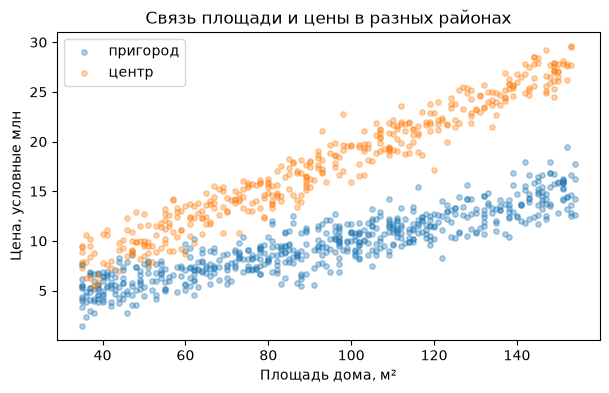

In [3]:
X_demo = X.copy()
X_demo["area_share"] = X_demo["area_m2"] / X_demo["plot_m2"].replace(0, np.nan)
X_demo["area_center"] = X_demo["area_m2"] * X_demo["district"].eq("центр").astype(int)

display(X_demo[["area_m2", "plot_m2", "district", "area_share", "area_center"]].head(8))

fig, ax = plt.subplots(figsize=(7, 4))
for district, part in X.assign(price_mln=y).groupby("district"):
    ax.scatter(part["area_m2"], part["price_mln"], s=15, alpha=0.35, label=district)
ax.set(xlabel="Площадь дома, м²", ylabel="Цена, условные млн", title="Связь площади и цены в разных районах")
ax.legend()
plt.show()

##### Шаг 3. Сравним три варианта одной модели

Используем одну и ту же линейную регрессию с одинаковыми CV-фолдами: исходные признаки, исходные признаки с отношением площадей и исходные признаки с взаимодействием. Обучаемые преобразования остаются внутри `Pipeline`.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler


def add_features(data):
    result = data.copy()
    result["area_share"] = result["area_m2"] / result["plot_m2"].replace(0, np.nan)
    result["area_center"] = result["area_m2"] * result["district"].eq("центр").astype(int)
    return result


def make_pipeline(extra_columns):
    numeric = ["area_m2", "plot_m2", "year_built"] + extra_columns
    prep = ColumnTransformer([
        ("numeric", StandardScaler(), numeric),
        ("district", OneHotEncoder(handle_unknown="ignore"), ["district"]),
    ])
    steps = []
    if extra_columns:
        steps.append(("feature_engineering", FunctionTransformer(add_features, validate=False)))
    return Pipeline(steps + [("preprocess", prep), ("model", LinearRegression())])


cv = KFold(n_splits=5, shuffle=True, random_state=42)
variants = {
    "Исходные признаки": [],
    "+ отношение площадей": ["area_share"],
    "+ взаимодействие": ["area_center"],
}

,Представление,MAE,SD по фолдам
0,Исходные признаки,1.546,0.122
1,+ отношение площадей,1.548,0.125
2,+ взаимодействие,0.973,0.062


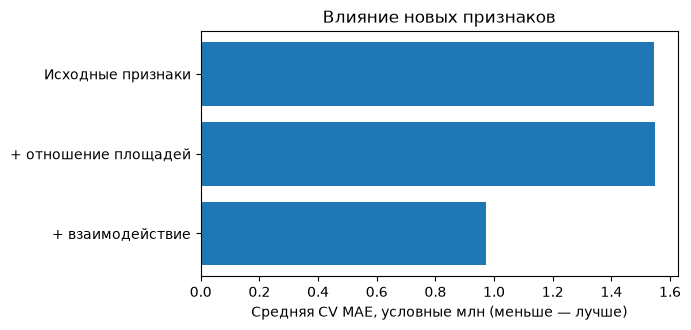

In [5]:
results = []
for name, columns in variants.items():
    # scikit-learn возвращает отрицательную MAE для совместимости с правилом «больше — лучше».
    fold_mae = -cross_val_score(
        make_pipeline(columns), X, y, cv=cv,
        scoring="neg_mean_absolute_error",
    )
    results.append({"Представление": name, "MAE": fold_mae.mean(), "SD по фолдам": fold_mae.std()})

results_df = pd.DataFrame(results)
display(results_df.round(3))

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(results_df["Представление"], results_df["MAE"])
ax.invert_yaxis()
ax.set(xlabel="Средняя CV MAE, условные млн (меньше — лучше)", title="Влияние новых признаков")
plt.tight_layout()
plt.show()

Отношение площадей не улучшает результат. Взаимодействие, напротив, заметно снижает ошибку: линейная модель получает возможность учитывать разные коэффициенты при площади в разных районах. Зависимость специально заложена в учебные данные; в настоящей задаче эффект любого нового признака придётся проверять.

Для модели с взаимодействием часть формулы выглядит так:

$$
\widehat y = \beta_0 + \beta_1\,\mathrm{area} + \beta_2 I(\mathrm{центр}) + \beta_3\,\mathrm{area}\,I(\mathrm{центр}) + \ldots
$$

В пригороде коэффициент при площади равен $\beta_1$, а в центре — $\beta_1+\beta_3$.

Для **kNN** механизм иной: добавление признака меняет расстояния между объектами. Новый столбец может как сделать соседей более похожими по смыслу задачи, так и испортить сравнение, особенно при неудачном масштабе.

#### Как проверять собственные гипотезы

**Наблюдение из EDA → гипотеза → новый признак → проверка на тех же CV-фолдах → вывод.**

Для каждого преобразования достаточно объяснить, что вы ожидали увидеть, как получили признак, что изменилось в качестве и оставляете ли вы его. Чтобы понять вклад именно FE, сравните два варианта с одинаковым алгоритмом и гиперпараметрами. Подбор настроек можно провести следующим этапом.

Помните о моменте прогноза: любой признак должен рассчитываться из информации, которая к этому моменту доступна. Если признак требует оценки статистик по выборке, его вычисление должно быть частью корректного обучающего Pipeline.

Отрицательная гипотеза тоже полезна, если эксперимент выполнен аккуратно. В ДЗ будем решать задачу классификации и сравнивать модели прежде всего по macro-F1; логика проверки остаётся той же.

##### Дополнительные материалы по FE

- [ODS на Хабре — Построение и отбор признаков](https://habr.com/ru/companies/ods/articles/325422/) — русскоязычный обзор; отдельные кодовые примеры могут быть устаревшими.
- [Kaggle Learn — Feature Engineering](https://www.kaggle.com/learn/feature-engineering) — в первую очередь *What Is Feature Engineering* и *Creating Features*.
- [Google ML Crash Course — Feature Crosses](https://developers.google.com/machine-learning/crash-course/categorical-data/feature-crosses) — взаимодействия в линейных моделях.
- [scikit-learn — L1 penalty and sparsity](https://scikit-learn.org/stable/auto_examples/linear_model/plot_logistic_l1_l2_sparsity.html) — как L1 влияет на коэффициенты.
- [scikit-learn — Compare scalers with outliers](https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html) — выбор преобразований при экстремальных значениях.

<a id="assignment"></a>

## II. Домашняя работа № 2: Сколько займёт поездка?

### Задача

Сервис заказа такси хочет заранее сообщать пассажиру примерное время в пути. По историческим данным о поездках в Нью-Йорке постройте модель, которая **перед началом поездки** определяет диапазон её длительности.

В работе нужно исследовать данные, сравнить логистическую регрессию и kNN, предложить собственные варианты feature engineering, проанализировать ошибки и выбрать итоговую модель.

| Класс | Продолжительность поездки |
|---|---|
| `0` | Меньше 5 минут |
| `1` | От 5 до 15 минут |
| `2` | От 15 до 30 минут |
| `3` | 30 минут и более |

При сравнении моделей ориентируйтесь прежде всего на **macro-F1**. Дополнительно изучайте accuracy, precision и recall, F1 по каждому классу и матрицу ошибок: одна итоговая цифра не даёт полной картины качества.

### Данные

Используем учебные выборки из [NYC Taxi Trip Duration](https://www.kaggle.com/competitions/nyc-taxi-trip-duration/data), построенные на исторических поездках в Нью-Йорке в 2016 году.

Предполагается, что **пункт назначения известен в момент заказа**; его координаты в таблице взяты из исторической записи поездки.

В `train.csv` сохраняются следующие поля исходной записи:

| Поле | Описание |
|---|---|
| `trip_id` | Идентификатор поездки для сопоставления строк и предсказаний |
| `vendor_id` | Код провайдера поездки |
| `pickup_datetime` | Время начала поездки |
| `dropoff_datetime` | Время завершения поездки |
| `passenger_count` | Число пассажиров |
| `pickup_longitude`, `pickup_latitude` | Координаты посадки |
| `dropoff_longitude`, `dropoff_latitude` | Координаты назначения |
| `store_and_fwd_flag` | Признак передачи записи из памяти устройства после отсутствия связи |
| `trip_duration` | Продолжительность поездки в секундах |
| `target` | Класс продолжительности поездки (0–3) |

Вам выдаются три файла:

| Файл | Объекты | Что доступно | Назначение |
|---|---:|---|---|
| `train.csv` | 80 000 | Исторические записи с `target` | Исследование, обучение, кросс-валидация |
| `test-public.csv` | 15 000 | Тестовые данные с `target` | Открытая проверка моделей |
| `test-private.csv` | 25 000 | Тестовые данные без `target` | Итоговые предсказания |

Все три файла выдаются одновременно. Перед моделированием самостоятельно выберите признаки, соответствующие постановке задачи и моменту прогноза.

In [6]:
from pathlib import Path
import os
import pandas as pd


def load_student_data(data_dir):
    """Прочитать три CSV без изменения их содержимого."""
    data_dir = Path(data_dir)
    train = pd.read_csv(data_dir / "train.csv")
    public = pd.read_csv(data_dir / "test-public.csv")
    private = pd.read_csv(data_dir / "test-private.csv")
    return train, public, private


DATA_DIR = Path(os.environ.get("HW02_DATA_DIR", "data"))  # Укажите свою папку.

train = public = private = None
if any((DATA_DIR / name).exists() for name in
       ["train.csv", "test-public.csv", "test-private.csv"]):
    train, public, private = load_student_data(DATA_DIR)
else:
    print("CSV пока не найдены. После получения файлов укажите их папку в DATA_DIR.")

CSV пока не найдены. После получения файлов укажите их папку в DATA_DIR.


### Что нужно сделать

Это единое небольшое исследование. Вы можете выбрать собственную структуру notebook, если по нему легко проследить ход работы и воспроизвести результаты.

#### 1. Познакомьтесь с данными и проведите EDA

Изучите значения и типы переменных, распределение классов, признаки, связанные с географией, временем и поездкой. Проверьте возможные аномалии и содержательные связи между характеристиками.

Представьте несколько наблюдений и выводов, которые повлияли на ваши дальнейшие решения. Для каждого важного вывода полезно пояснить, что обнаружено и какую гипотезу или действие это подсказало. **Количество графиков не ограничено:** выбирайте те, которые действительно помогают исследованию.

#### 2. Обучите и сравните baseline-модели

Постройте `DummyClassifier`, логистическую регрессию (`LogisticRegression`) и метод ближайших соседей (`KNeighborsClassifier`). Продумайте представление числовых, категориальных и временных признаков.

Используйте кросс-валидацию на `train`, сравните модели по macro-F1 и другим выбранным метрикам. Объясните, как организовали проверку и почему полученным результатам можно доверять.

#### 3. Настройте модели

Проведите небольшой обоснованный подбор гиперпараметров LR и kNN, например с помощью `GridSearchCV`. Покажите, какие варианты сравнивали, какие выбрали и почему.

Не требуется огромный перебор или обязательное обучение на всех 80 тысячах после каждой небольшой правки. Итоговые сравнения должны опираться на единый корректный протокол.

#### 4. Feature engineering: собственные гипотезы

Предложите и экспериментально проверьте **не менее двух содержательно разных гипотез** о новых признаках или представлениях уже имеющейся информации.

Для каждой гипотезы покажите:

1. Откуда возникла идея — наблюдение EDA, смысл задачи или рассуждение о возможностях алгоритма.
2. Что именно изменилось в признаках и почему это может помочь.
3. Как организовано сравнение «до/после» на одинаковых CV-разбиениях.
4. Что получилось и какой вывод можно сделать.

Хотя бы в одном сравнении сохраните **тот же алгоритм и те же гиперпараметры**, изменив только представление признаков: так будет понятнее, какой эффект даёт именно FE. После этого можно отдельно выполнить дополнительную настройку.

**Не требуется, чтобы все гипотезы улучшили метрику.** Корректный эксперимент с отрицательным результатом и осмысленной интерпретацией ценнее, чем неподтверждённое утверждение о «полезных» признаках. Количество добавленных столбцов само по себе не оценивается.

#### 5. Разберите ошибки и выберите модель

Сравните хотя бы две содержательно разные конфигурации. Посмотрите на качество отдельных классов, confusion matrix и характерные ошибки. Для каких поездок модель ошибается чаще? Можно ли связать это с результатами EDA или устройством признаков?

Объясните выбор финальной конфигурации и её ограничения. Для анализа ошибок используйте проверочные предсказания, а не результаты на тех же объектах, на которых модель обучалась.

#### 6. Проверьте решения на `test-public`

Выбирайте модели и их настройки прежде всего по результатам кросс-валидации на `train`. На открытом `test-public` можно проверить разные версии и сравнить результаты с CV, обсудить расхождения и при необходимости вернуться к исследованию. Учитывайте, что многократная настройка по открытому тесту делает его оценку менее независимой.

Объекты `test-public` не добавляйте в обучающую выборку и не используйте для вычисления статистик обучаемых преобразований.

#### 7. Подготовьте предсказания для `test-private`

В `test-private.csv` нет правильных меток. Примените к этим поездкам выбранную модель и создайте файл `submission.csv` с двумя колонками:

```text
trip_id,prediction
```

`prediction` — число `0`, `1`, `2` или `3`. В файле должна быть одна строка для каждого `trip_id` из `test-private.csv`, без пропусков и повторов.

Например, если переменная `private` содержит входную таблицу, а `predictions` — предсказанные классы в том же порядке, файл можно сформировать так:

In [7]:
# Пример сохранения предсказаний после обучения вашей модели:
# submission = pd.DataFrame({"trip_id": private["trip_id"], "prediction": predictions})
# submission.to_csv("submission.csv", index=False)

### Что сдавать

- **Jupyter notebook (`.ipynb`)** с кодом, результатами экспериментов, графиками и комментариями. Его должно быть можно выполнить по порядку при наличии данных.
- **`submission.csv`** с предсказаниями для `test-private`.

Отдельный PDF или презентация не нужны. Для основной работы достаточно логистической регрессии и kNN (плюс Dummy как ориентир).

Сроки и способ отправки файлов будут объявлены отдельно.

<a id="recommendations"></a>

## III. Рекомендации по выполнению и оформлению

Работа может идти по такой схеме:

`Данные → EDA → baseline → CV и подбор → FE → анализ ошибок → итоговый выбор → test-public → submission`.

Для сравнения конфигураций удобно использовать **одинаковые CV-разбиения**. При неравных частотах классов можно взять `StratifiedKFold`. Все преобразования, которые обучаются по данным, размещайте в `Pipeline` или организуйте эквивалентно корректный процесс обучения внутри CV.

##### Ведите понятный журнал экспериментов

| Гипотеза / изменение | Что сравнили | CV до | CV после | Вывод |
|---|---|---:|---:|---|
| *Ваш вариант* | *Одна модель, одинаковые фолды* | … | … | … |

##### Оформляйте notebook для читателя

- Разбейте работу на разделы и, где нужно, подразделы: Markdown-заголовки помогают ориентироваться.
- В начале полезно дать краткое содержание или путеводитель: что в работе исследовано и где искать основные результаты.
- Поясняйте решения рядом с кодом и графиками: что проверяли, что получилось, как интерпретировали результат.
- Таблицы с итогами экспериментов понятнее, чем длинные несвязанные логи. Не оставляйте в финальной версии десятки случайных промежуточных выводов.
- В конце кратко сведите результаты: какая модель выбрана, что помогло, что не сработало, где остаются ошибки и ограничения.

Итоговый notebook — **артефакт для читателя**. По нему должно быть понятно, что вы сделали с данными, какие модели проверили и почему пришли к выбранному решению. Это важнее, чем следовать какому-то единственному шаблону ячеек.

Перед сдачей проверьте запуск сверху вниз и соответствие `trip_id` в `submission.csv` исходному `test-private.csv`.

---

### Теперь ваша очередь

Можно начать работу прямо ниже или создать отдельный notebook. Удачи!

In [8]:
# Your code here